# Lab 5: The Deutsch Algorithm - A First Glimpse of Quantum Speedup

Welcome to Lab 5! In our previous labs, we explored the foundational properties of quantum mechanics like superposition and entanglement, and we even saw how entanglement could revolutionize communication with superdense coding. Now, we shift our focus from communication to **computation** and investigate one of the first algorithms to demonstrate that a quantum computer could be more powerful than a classical one: the **Deutsch algorithm**.

Imagine you are given a "black box" or an "oracle" that computes a function `f(x)` which takes a single bit (`0` or `1`) and returns a single bit. You are promised that the function is either **constant** (it returns the same value for all inputs, i.e., `f(0) = f(1)`) or **balanced** (it returns different values for each input, i.e., `f(0) ≠ f(1)`). Classically, how many times would you need to check the function to be certain of its type? You'd have to check it twice: once for `f(0)` and once for `f(1)`.

The Deutsch algorithm provides a stunning quantum solution. By leveraging the principles of superposition and interference, it can determine whether the function is constant or balanced with just **one single query** to the oracle. This marks our first encounter with a true **quantum speedup**, where a quantum approach is provably more efficient than any possible classical method.

In this lab, we will:
*   Implement the Deutsch algorithm to distinguish between constant and balanced functions.
*   Construct quantum circuits that act as "oracles" for all four possible one-bit functions (two constant, two balanced).
*   Prepare the initial quantum state and apply the necessary Hadamard gates to create superposition.
*   Run the algorithm for each of the four oracles on the **`qasm_simulator`**.
*   Observe the measurement outcomes, confirming that a result of `0` always corresponds to a constant function and a result of `1` always corresponds to a balanced function.
*   Witness a foundational example of how quantum parallelism allows us to gain information about a function's global properties more efficiently than classical computation.

Let's explore our first quantum algorithm and witness how superposition and interference lead to a genuine computational advantage.

In [1]:
%pip install qiskit qiskit-aer matplotlib
%pip install pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 40.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 65.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 78.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [2]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library

## Constant Oracles - Oracle with Identity Gates

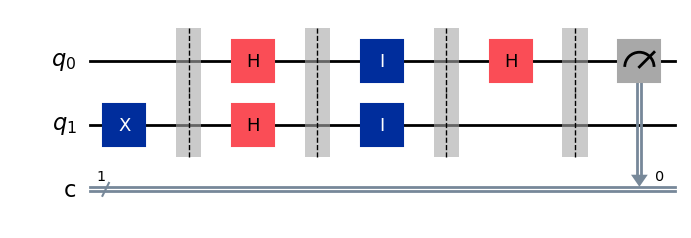

In [3]:
# Implement Deutsch Algorithm for a Constant Function
qc = QuantumCircuit(2,1,name="qc")

# Place the second qubit in state |1>
qc.x(1)
qc.barrier()

# Place each qubit in Superposition
qc.h(0)
qc.h(1)
qc.barrier()

# Creating a constant oracle
qc.id(0)
qc.id(1)
qc.barrier()

# Putting a Hadamard to the first qubit
qc.h(0)
qc.barrier()

# Measuring the first qubit
qc.measure(0,0)

qc.draw('mpl')


Total counts are: {'0': 1000}


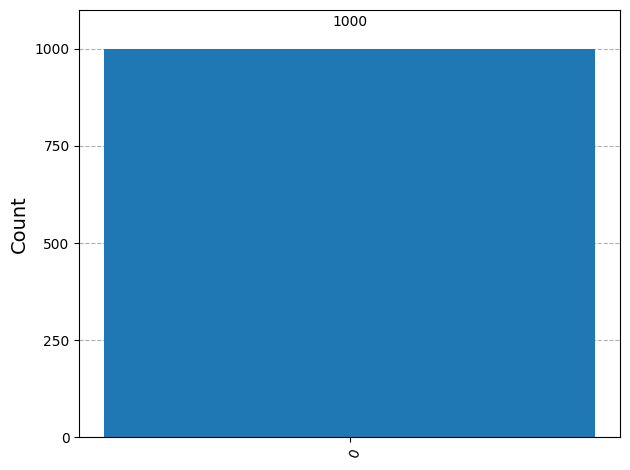

In [4]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qc)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## Constant Oracles - Oracle with X Gate on Second Qubit

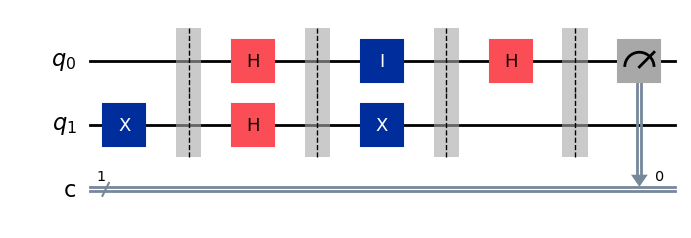

In [5]:
# Implement Deutsch Algorithm for a Constant Function
qc = QuantumCircuit(2,1,name="qc")

# Place the second qubit in state |1>
qc.x(1)
qc.barrier()

# Place each qubit in Superposition
qc.h(0)
qc.h(1)
qc.barrier()

# Creating a constant oracle
qc.id(0)
qc.x(1)
qc.barrier()

# Putting a Hadamard to the first qubit
qc.h(0)
qc.barrier()

# Measuring the first qubit
qc.measure(0,0)

qc.draw('mpl')


Total counts are: {'0': 1000}


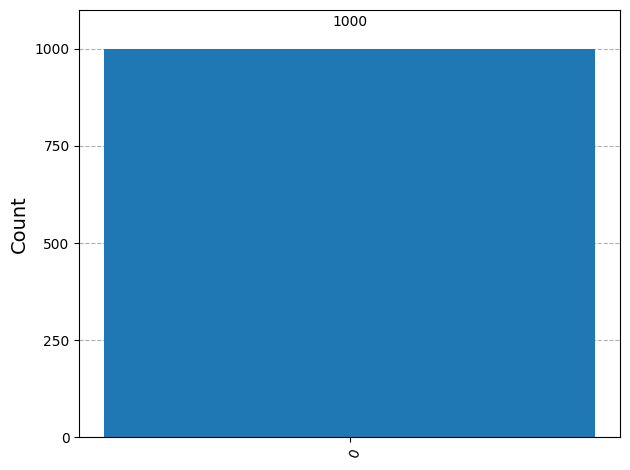

In [6]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit on the qasm_simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qc)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## Balanced Oracles - Oracle with CX Gate

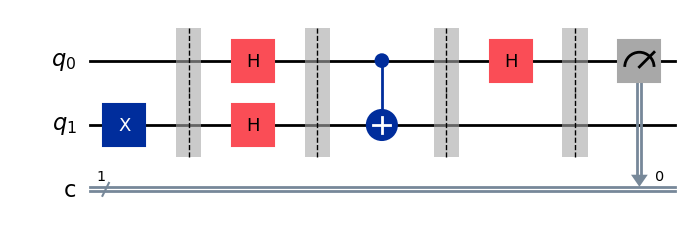

In [7]:
# Implement Deutsch Algorithm for a Balanced Function
qc = QuantumCircuit(2,1,name="qc")

# Place the second qubit in state |1>
qc.x(1)
qc.barrier()

# Place each qubit in Superposition
qc.h(0)
qc.h(1)
qc.barrier()

# Creating a balanced oracle
qc.cx(0,1)
qc.barrier()

# Putting a Hadamard to the first qubit
qc.h(0)
qc.barrier()

# Measuring the first qubit
qc.measure(0,0)

qc.draw('mpl')


Total counts are: {'1': 1000}


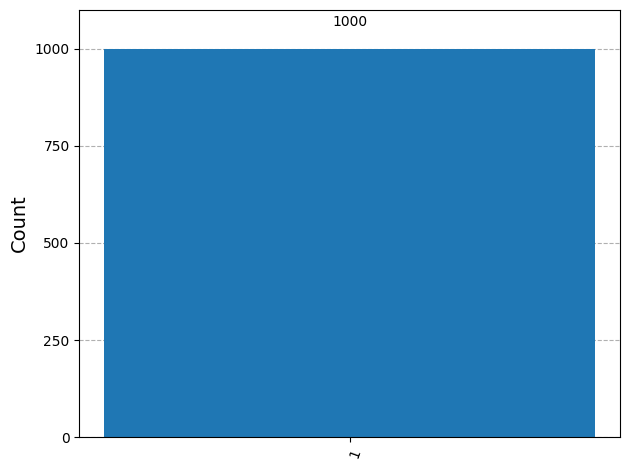

In [8]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qc)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

## Balanced Oracles - Oracle with CX Gate with X Gate

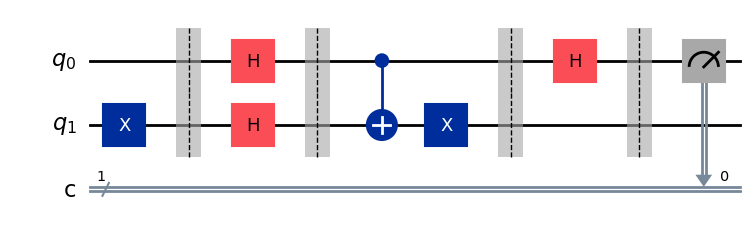

In [9]:
# Implement Deutsch Algorithm for a Balanced Function
qc = QuantumCircuit(2,1,name="qc")

# Place the second qubit in state |1>
qc.x(1)
qc.barrier()

# Place each qubit in Superposition
qc.h(0)
qc.h(1)
qc.barrier()

# Creating a balanced oracle
qc.cx(0,1)
qc.x(1)
qc.barrier()

# Putting a Hadamard to the first qubit
qc.h(0)
qc.barrier()

# Measuring the first qubit
qc.measure(0,0)

qc.draw('mpl')


Total counts are: {'1': 1000}


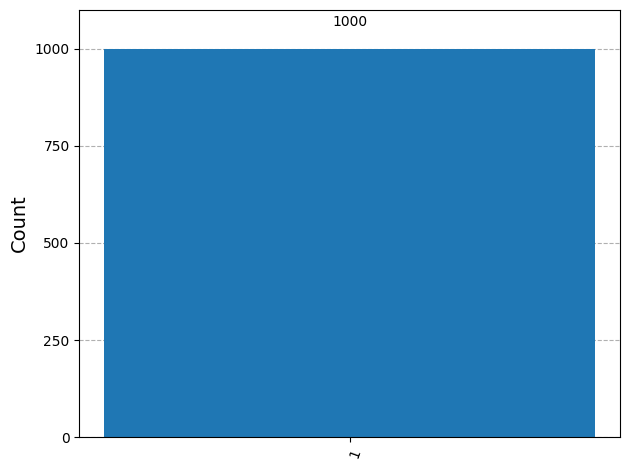

In [10]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

# Execute the circuit on the qasm simulator
transpiled_qc = transpile(qc, backend)

job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qc)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)